# 📘 AUDITORÍA DE IDENTIFICABILIDAD EN VENTANA EXTENDIDA (DATASET D2)
## Prueba Directa de la Pared Temporal: 12 Archivos de Evento Único (Diseño Factorial 2×2)

### Protocolo Pre-registrado (Antes de inspeccionar los datos)
A diferencia del Dataset D1 (4 archivos con 5 pulsaciones concatenadas de $0.80\text{–}0.99\text{ s}$), el **Dataset D2** consta de **12 grabaciones independientes** (3 repeticiones por condición) donde la cuerda Sol ($G_3, f_0 \approx 196\text{ Hz}$) se pulsa una única vez y se deja decaer libremente hasta extinguirse en el piso de ruido:
* **XLR** $\rightarrow$ Captación por micrófono (`dedo` / `púa`, 3 archivos c/u).
* **Jack** $\rightarrow$ Captación por línea piezoeléctrica (`dedo` / `púa`, 3 archivos c/u).

### Criterios de Decisión Pre-registrados (Rama A vs. Rama B)
1. **Rama A (Confirmación de Pared Temporal en ventana extendida):** Al extender la ventana de observación más allá de $1\text{ s}$, $\beta_{\text{eff}}(t) = -t\,\frac{d\ln A}{dt}$ sigue la rampa exponencial $\sigma t$ y colapsa hacia $\beta_{\text{eff}} \approx 0$ al tocar el piso de ruido ambiental, sin estabilizarse en ninguna meseta fraccionaria $\alpha \in (0, 1)$.
2. **Rama B (Resultado positivo de cola):** Aparece una meseta estable (plateau con $\text{IQR} < 0.25$) en $\beta_{\text{eff}}(t) \in (0.1, 0.9)$ por encima del piso de ruido antes de la extinción, obligando a revisar la cota teórica $r = B_\alpha/A_0 \lesssim 10^{-7}$.

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9.0,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

print('✅ Entorno configurado para Auditoría D2 (Ventana Extendida).')
print(f' - NumPy v{np.__version__} | SciPy v{scipy.__version__} | Librosa v{librosa.__version__}\n')

# Carga de los 12 archivos WAV del Dataset D2
archivos_wav = sorted([f for f in os.listdir('.') if f.lower().endswith('.wav') and ('xlr' in f.lower() or 'jack' in f.lower())])

if len(archivos_wav) < 12:
    try:
        from google.colab import files
        print('📂 Sube los 12 archivos .wav del Dataset D2 (XLR/Jack, dedo/pua):')
        uploaded = files.upload()
        archivos_wav = sorted(list(uploaded.keys()))
    except ImportError:
        pass

def clasificar_condicion(nombre_archivo):
    low = nombre_archivo.lower()
    captacion = 'mic' if 'xlr' in low else ('linea' if 'jack' in low else 'desconocido')
    excitacion = 'pua' if 'pua' in low else ('dedo' if 'dedo' in low else 'desconocido')
    return f'{excitacion}_{captacion}', excitacion, captacion

datos_d2 = {}
print(f'\n🔄 Verificando integridad de {len(archivos_wav)} archivos (Regla R-N3: Duración real)...')
print('='*90)
for nombre in archivos_wav:
    y, sr = librosa.load(nombre, sr=None, mono=True)
    cond, exc, cap = clasificar_condicion(nombre)
    dur_total = len(y) / sr
    datos_d2[nombre] = {
        'senal': y,
        'sr': sr,
        'condicion': cond,
        'excitacion': exc,
        'captacion': cap,
        'duracion_archivo': dur_total
    }
    print(f' ✅ {nombre:20s} | Cond: {cond:10s} | fs: {sr} Hz | Duración archivo: {dur_total:5.2f} s | Muestras: {len(y)}')

✅ Entorno configurado para Auditoría D2 (Ventana Extendida).
 - NumPy v2.4.6 | SciPy v1.16.3 | Librosa v0.11.0


🔄 Verificando integridad de 12 archivos (Regla R-N3: Duración real)...
 ✅ Jack dedo_002.wav    | Cond: dedo_linea | fs: 48000 Hz | Duración archivo:  9.43 s | Muestras: 452646
 ✅ Jack dedo_003.wav    | Cond: dedo_linea | fs: 48000 Hz | Duración archivo: 10.33 s | Muestras: 495654
 ✅ Jack dedo_004.wav    | Cond: dedo_linea | fs: 48000 Hz | Duración archivo:  9.98 s | Muestras: 479270
 ✅ Jack pua_006.wav     | Cond: pua_linea  | fs: 48000 Hz | Duración archivo:  9.79 s | Muestras: 470054
 ✅ Jack pua_007.wav     | Cond: pua_linea  | fs: 48000 Hz | Duración archivo:  9.65 s | Muestras: 463398
 ✅ Jack pua_008.wav     | Cond: pua_linea  | fs: 48000 Hz | Duración archivo: 10.38 s | Muestras: 498214
 ✅ XLR dedo_005.wav     | Cond: dedo_mic   | fs: 48000 Hz | Duración archivo: 10.52 s | Muestras: 505126
 ✅ XLR dedo_006.wav     | Cond: dedo_mic   | fs: 48000 Hz | Duración archivo: 10.

---
# ✂️ Sección 1: Filtrado Fundamental ($196\text{ Hz}$) y Segmentación de Evento Único Extendido

A diferencia de D1, aquí **no truncamos el segmento a $0.80\text{ s}$**. Detectamos el único ataque principal del archivo, medimos el piso de ruido ambiental estrictamente **antes** del impacto (Regla **R-N4**), descartamos los primeros $50\text{ ms}$ de transitorio no lineal y dejamos correr la ventana hasta que la envolvente alcanza $2.5\times$ el piso de ruido de banda (o el final de la grabación), imprimiendo la duración real resultante (**R-N3**).

In [ ]:
def disenar_filtro_sos(f_central, bw, fs, orden=2):
    nyq = 0.5 * fs
    low = max((f_central - bw / 2.0) / nyq, 0.001)
    high = min((f_central + bw / 2.0) / nyq, 0.999)
    return signal.butter(orden, [low, high], btype='bandpass', output='sos')

F0_SOL = 196.0
BW_FUND = 20.0  # [186 Hz, 206 Hz]

eventos_d2 = {}
print('🚀 SEGMENTACIÓN DE EVENTO ÚNICO Y AUDITORÍA DE DURACIÓN ÚTIL / SNR VERDADERO (R-N3, R-N4)')
print('='*96)

for nombre, info in datos_d2.items():
    y = info['senal']
    sr = info['sr']
    sos = disenar_filtro_sos(F0_SOL, BW_FUND, sr, orden=2)
    y_filt = signal.sosfiltfilt(sos, y)

    # Envolvente RMS suave (20 ms) para localizar el único ataque principal
    win_samples = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_samples)/win_samples, mode='same'))
    pk = int(np.argmax(rms_env))
    pico_val = rms_env[pk]

    # Piso de ruido PRE-ATAQUE (desde 0.10 s hasta 0.15 s antes del pico)
    pre_ini = int(0.10 * sr)
    pre_fin = max(int(0.25 * sr), pk - int(0.15 * sr))
    if pre_fin <= pre_ini:
        ruido_pre_rms = np.sqrt(np.mean(y_filt[-int(0.30*sr):]**2)) + 1e-12
    else:
        ruido_pre_rms = np.sqrt(np.mean(y_filt[pre_ini:pre_fin]**2)) + 1e-12

    # Inicio tras 50 ms de ataque; fin extendido hasta alcanzar piso de ruido (2.5x RMS pre-ataque)
    inicio = pk + int(0.05 * sr)
    limite_archivo = len(y_filt) - int(0.05 * sr)
    env_post = rms_env[inicio:limite_archivo]

    umbral_ruido = 2.5 * ruido_pre_rms
    cruce_ruido = np.where(env_post < umbral_ruido)[0]

    if len(cruce_ruido) > 0:
        fin_util = inicio + cruce_ruido[0]
        motivo_corte = 'Alcanzó piso de ruido'
    else:
        fin_util = limite_archivo
        motivo_corte = 'Fin de grabación'

    # Ventana ampliada (+1.5 s extra sobre el piso de ruido) para ver el colapso de beta_eff -> 0
    fin_extendido = min(fin_util + int(1.5 * sr), limite_archivo)

    snr_true = 20 * np.log10((pico_val + 1e-12) / ruido_pre_rms)
    dur_util = (fin_util - inicio) / sr
    dur_ext = (fin_extendido - inicio) / sr

    # Hilbert sobre la ventana extendida
    seg_ext = y_filt[inicio:fin_extendido]
    env_hilbert = np.abs(signal.hilbert(seg_ext))
    n_cut = int(0.03 * sr)
    env_clean = env_hilbert[n_cut:-n_cut]
    t_clean = np.arange(len(env_clean)) / sr + 0.05 + 0.03

    # Estimación de tau y Bedrosian eta en la zona útil
    n_util_clean = max(int((dur_util - 0.06) * sr), int(0.3 * sr))
    n_util_clean = min(n_util_clean, len(env_clean))
    p_exp, _ = np.polyfit(t_clean[:n_util_clean], np.log(env_clean[:n_util_clean] + 1e-12), 1)
    sigma_est = max(-p_exp, 0.1)
    tau_est = 1.0 / sigma_est
    eta_tau = F0_SOL * tau_est

    eventos_d2[nombre] = {
        'condicion': info['condicion'],
        'y_filt': y_filt,
        'sr': sr,
        't_ataque': pk / sr,
        'inicio_idx': inicio,
        'fin_util_idx': fin_util,
        'dur_archivo': info['duracion_archivo'],
        'dur_util': dur_util,
        'dur_ext': dur_ext,
        'ruido_pre_rms': ruido_pre_rms,
        'snr_true_db': snr_true,
        'sigma_util': sigma_est,
        'eta_tau': eta_tau,
        't_ext': t_clean,
        'env_ext': env_clean,
        'n_util_clean': n_util_clean
    }
    print(f"📁 {nombre:20s} [{info['condicion']:10s}] | File: {info['duracion_archivo']:5.2f}s | "
          f"Decaim. útil: {dur_util:5.2f}s (Ext: {dur_ext:5.2f}s) | SNR_true: {snr_true:4.1f}dB | η: {eta_tau:4.1f} ({motivo_corte})")

🚀 SEGMENTACIÓN DE EVENTO ÚNICO Y AUDITORÍA DE DURACIÓN ÚTIL / SNR VERDADERO (R-N3, R-N4)
📁 Jack dedo_002.wav    [dedo_linea] | File:  9.43s | Decaim. útil:  5.29s (Ext:  6.79s) | SNR_true: 68.6dB | η: 220.5 (Alcanzó piso de ruido)
📁 Jack dedo_003.wav    [dedo_linea] | File: 10.33s | Decaim. útil:  5.48s (Ext:  6.98s) | SNR_true: 70.7dB | η: 208.2 (Alcanzó piso de ruido)
📁 Jack dedo_004.wav    [dedo_linea] | File:  9.98s | Decaim. útil:  5.44s (Ext:  6.94s) | SNR_true: 71.0dB | η: 208.6 (Alcanzó piso de ruido)
📁 Jack pua_006.wav     [pua_linea ] | File:  9.79s | Decaim. útil:  4.26s (Ext:  5.76s) | SNR_true: 57.9dB | η: 170.2 (Alcanzó piso de ruido)
📁 Jack pua_007.wav     [pua_linea ] | File:  9.65s | Decaim. útil:  6.55s (Ext:  7.12s) | SNR_true: 70.1dB | η: 215.4 (Alcanzó piso de ruido)
📁 Jack pua_008.wav     [pua_linea ] | File: 10.38s | Decaim. útil:  4.23s (Ext:  5.73s) | SNR_true: 53.4dB | η: 185.9 (Alcanzó piso de ruido)
📁 XLR dedo_005.wav     [dedo_mic  ] | File: 10.52s | Decaim

---
# 🧱 Sección 2: Evolución de $\beta_{\text{eff}}(t)$ en Todo el Decaimiento y Veredicto Rama A vs. Rama B

Evaluamos la derivada logarítmica instantánea $\beta_{\text{eff}}(t) = -t\,\frac{d\ln A(t)}{dt}$ a lo largo de **toda** la ventana extendida, reportando la **mediana e IQR** (Regla **R-N1**) en tres tramos temporales:
* **Tramo Temprano ($0.15\text{–}0.65\text{ s}$):** Régimen equivalente a D1.
* **Tramo Extendido ($0.65\text{ s} \to t_{\text{ruido}}$):** Ventana ganada gracias al protocolo de evento único D2.
* **Tramo Final / Piso de Ruido ($> t_{\text{ruido}}$):** Donde la señal queda dominada por ruido estacionario ($\beta_{\text{eff}} \to 0$).

🔬 EVALUACIÓN DE β_eff(t) EN VENTANA EXTENDIDA (REGLA R-N1: MEDIANA E IQR)
Jack dedo_002.wav    | σ=0.89s⁻¹ | RSS_POT/EXP= 0.78 | β_ext(0.65s..t_ruido)=2.43 (IQR 2.89) | β_ruido=1.37 -> RAMA A (Pared Temporal confirmada)
Jack dedo_003.wav    | σ=0.94s⁻¹ | RSS_POT/EXP= 0.71 | β_ext(0.65s..t_ruido)=2.62 (IQR 2.32) | β_ruido=2.25 -> RAMA A (Pared Temporal confirmada)
Jack dedo_004.wav    | σ=0.94s⁻¹ | RSS_POT/EXP= 0.66 | β_ext(0.65s..t_ruido)=2.54 (IQR 2.18) | β_ruido=3.24 -> RAMA A (Pared Temporal confirmada)
Jack pua_006.wav     | σ=1.15s⁻¹ | RSS_POT/EXP= 2.60 | β_ext(0.65s..t_ruido)=2.26 (IQR 1.85) | β_ruido=2.83 -> RAMA A (Pared Temporal confirmada)
Jack pua_007.wav     | σ=0.91s⁻¹ | RSS_POT/EXP= 5.02 | β_ext(0.65s..t_ruido)=2.35 (IQR 2.35) | β_ruido=2.73 -> RAMA A (Pared Temporal confirmada)
Jack pua_008.wav     | σ=1.05s⁻¹ | RSS_POT/EXP= 3.61 | β_ext(0.65s..t_ruido)=2.14 (IQR 1.41) | β_ruido=3.77 -> RAMA A (Pared Temporal confirmada)
XLR dedo_005.wav     | σ=1.04s⁻¹ | RSS_POT/EXP= 0.

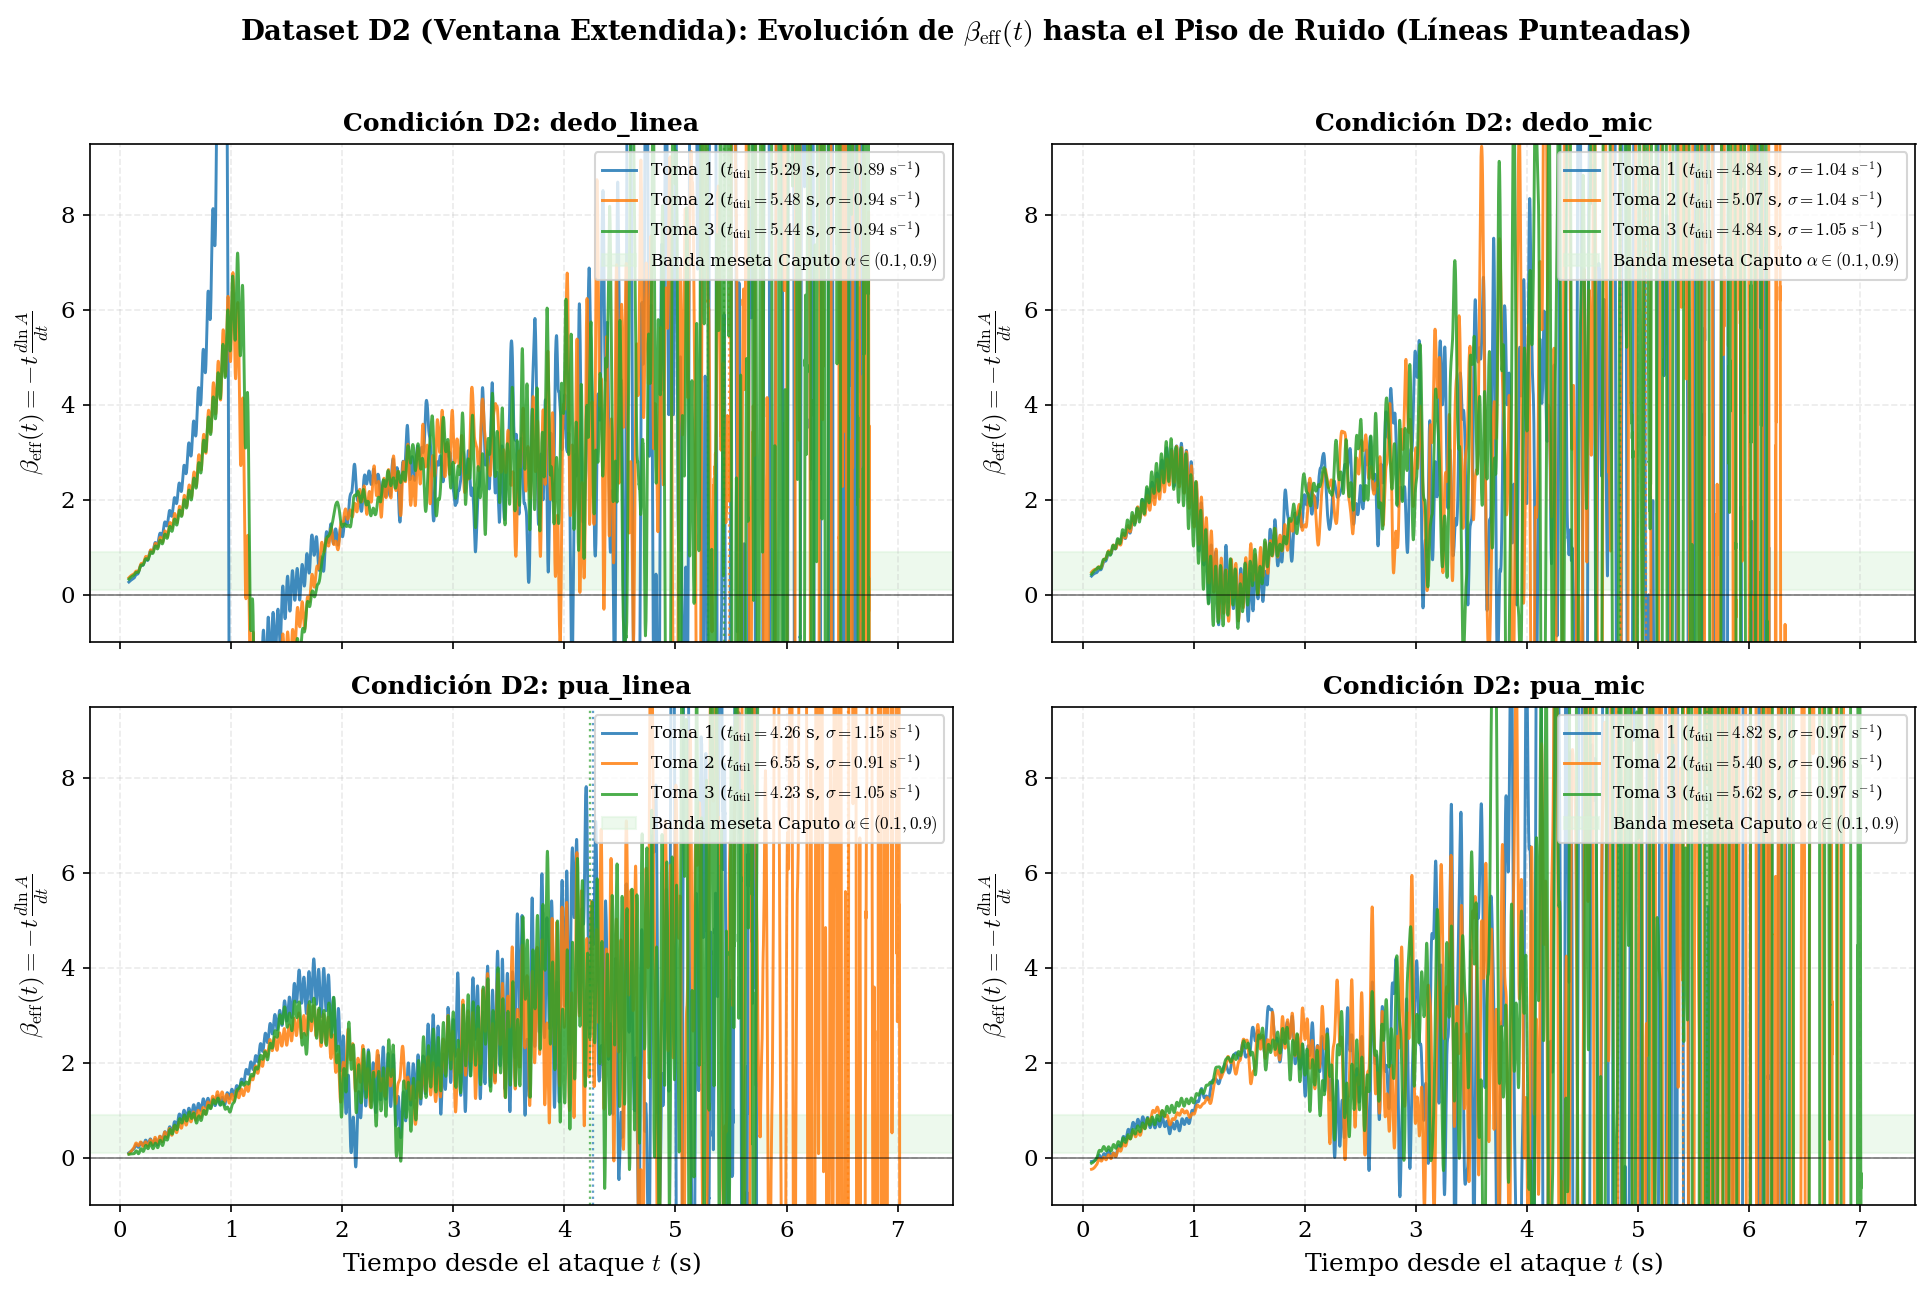


💾 Exportado: D2_auditoria_ventana_extendida.csv y Fig_D2_beta_eff_Ventana_Extendida.pdf


In [ ]:
filas_d2 = []
print('🔬 EVALUACIÓN DE β_eff(t) EN VENTANA EXTENDIDA (REGLA R-N1: MEDIANA E IQR)')
print('='*98)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
axes = axes.flatten()
condiciones_orden = ['dedo_linea', 'dedo_mic', 'pua_linea', 'pua_mic']
colores_rep = ['#1f77b4', '#ff7f0e', '#2ca02c']

for nombre, ev in eventos_d2.items():
    sr = ev['sr']
    t = ev['t_ext']
    env = ev['env_ext']
    log_env = np.log(env + 1e-12)

    # Suavizado Savitzky-Golay (ventana 90 ms) para filtrar el batido de ~8 Hz sin destruir tendencia
    win_sg = min(int(0.09 * sr) | 1, len(log_env) - 2)
    dlogA_dt = signal.savgol_filter(log_env, window_length=win_sg, polyorder=2, deriv=1, delta=1.0/sr)
    beta_eff = -t * dlogA_dt
    ev['beta_eff'] = beta_eff

    # Comparación EXP vs POT en toda la ventana útil (Regla R-N2: razón de RSS)
    nu = ev['n_util_clean']
    t_u, le_u = t[:nu], log_env[:nu]
    rss_exp = np.sum((le_u - np.polyval(np.polyfit(t_u, le_u, 1), t_u))**2)
    rss_pot = np.sum((le_u - np.polyval(np.polyfit(np.log(t_u), le_u, 1), np.log(t_u)))**2)
    razon_rss = rss_pot / (rss_exp + 1e-12)

    # Estadísticos robustos (Mediana e IQR) por tramo temporal (R-N1)
    m_temprano = (t >= 0.15) & (t <= 0.65)
    m_extendido = (t > 0.65) & (t <= ev['dur_util'])
    m_ruido = (t > ev['dur_util'])

    b_temp_med = np.median(beta_eff[m_temprano]) if np.any(m_temprano) else np.nan
    b_temp_iqr = (np.percentile(beta_eff[m_temprano], 75) - np.percentile(beta_eff[m_temprano], 25)) if np.any(m_temprano) else np.nan

    b_ext_med = np.median(beta_eff[m_extendido]) if np.any(m_extendido) else np.nan
    b_ext_iqr = (np.percentile(beta_eff[m_extendido], 75) - np.percentile(beta_eff[m_extendido], 25)) if np.any(m_extendido) else np.nan

    b_ruido_med = np.median(beta_eff[m_ruido]) if np.any(m_ruido) else np.nan

    # Criterio automático Rama A vs Rama B
    es_meseta_frac = (0.10 <= b_ext_med <= 0.90) and (b_ext_iqr < 0.25) and (razon_rss < 0.8)
    veredicto = 'RAMA B (Posible meseta)' if es_meseta_frac else 'RAMA A (Pared Temporal confirmada)'

    filas_d2.append({
        'archivo': nombre,
        'condicion': ev['condicion'],
        'dur_archivo_s': ev['dur_archivo'],
        'dur_util_s': ev['dur_util'],
        'SNR_true_dB': ev['snr_true_db'],
        'sigma_s_inv': ev['sigma_util'],
        'RSS_POT_sobre_RSS_EXP': razon_rss,
        'beta_temprano_med': b_temp_med,
        'beta_temprano_IQR': b_temp_iqr,
        'beta_extendido_med': b_ext_med,
        'beta_extendido_IQR': b_ext_iqr,
        'beta_piso_ruido_med': b_ruido_med,
        'veredicto': veredicto
    })
    print(f"{nombre:20s} | σ={ev['sigma_util']:4.2f}s⁻¹ | RSS_POT/EXP={razon_rss:5.2f} | "
          f"β_ext(0.65s..t_ruido)={b_ext_med:4.2f} (IQR {b_ext_iqr:4.2f}) | β_ruido={b_ruido_med:4.2f} -> {veredicto}")

# Graficar las 4 condiciones del diseño 2x2
for idx_c, cond in enumerate(condiciones_orden):
    ax = axes[idx_c]
    evs_cond = [v for v in eventos_d2.values() if v['condicion'] == cond]
    for r_i, ev in enumerate(evs_cond):
        lbl = rf'Toma {r_i+1} ($t_{{\mathrm{{útil}}}}={ev["dur_util"]:.2f}$ s, $\sigma={ev["sigma_util"]:.2f}\ \mathrm{{s}}^{{-1}}$)'
        ax.plot(ev['t_ext'], ev['beta_eff'], color=colores_rep[r_i], lw=1.4, alpha=0.85, label=lbl)
        ax.axvline(ev['dur_util'], color=colores_rep[r_i], ls=':', lw=1.1, alpha=0.7)
    ax.axhspan(0.1, 0.9, color='#d9f2d9', alpha=0.45, label=r'Banda meseta Caputo $\alpha \in (0.1, 0.9)$')
    ax.axhline(0, color='black', lw=0.8, alpha=0.5)
    ax.set_title(f'Condición D2: {cond}', fontweight='bold')
    ax.set_ylabel(r'$\beta_{\mathrm{eff}}(t) = -t\,\frac{d\ln A}{dt}$')
    ax.set_ylim(-1.0, 9.5)
    ax.legend(loc='upper right', fontsize=8.2, frameon=True)

for ax in axes[2:]:
    ax.set_xlabel('Tiempo desde el ataque $t$ (s)')

plt.suptitle(r'Dataset D2 (Ventana Extendida): Evolución de $\beta_{\mathrm{eff}}(t)$ hasta el Piso de Ruido (Líneas Punteadas)', y=1.01, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig_D2_beta_eff_Ventana_Extendida.pdf', bbox_inches='tight')
plt.show()

df_d2 = pd.DataFrame(filas_d2)
df_d2.to_csv('D2_auditoria_ventana_extendida.csv', index=False)
print('\n💾 Exportado: D2_auditoria_ventana_extendida.csv y Fig_D2_beta_eff_Ventana_Extendida.pdf')

---
# 🎸 Sección 3: Espectroscopía Modal (Ruta R1) sobre el Dataset D2 ($n = 1\dots 6$)

Extracción de las tasas modales $\sigma_n$ mediante **mediana e IQR** (Regla **R-N1**), verificación de $\text{SNR}_{\text{true}} \ge 20\text{ dB}$ contra el piso de ruido pre-ataque de cada banda armónica (**R-N4**) y separación $\eta_n$ de Bedrosian, invirtiendo $\sigma_n = (T/L)\,\text{Re}[Y(\omega_n)]$ ($T/L = 107.7\text{ kg/s}^2$) para contrastar la reproducibilidad de la admitancia del puente entre **D1** y **D2**.

In [ ]:
T_SOBRE_L = 107.7
ARMONICOS = [1, 2, 3, 4, 5, 6]

filas_r1_d2 = []
print('🎵 RUTA R1 EN DATASET D2: TASAS MODALES σ_n, SNR_true, η Y ADMITANCIA Re[Y(ω_n)]')
print('='*96)

for nombre, info in datos_d2.items():
    y = info['senal']
    sr = info['sr']
    ev = eventos_d2[nombre]
    pk = int(ev['t_ataque'] * sr)
    inicio = ev['inicio_idx']
    fin_util = ev['fin_util_idx']

    for n in ARMONICOS:
        fn = n * F0_SOL
        omega_n = 2 * np.pi * fn
        sos_n = disenar_filtro_sos(fn, BW_FUND, sr, orden=2)
        y_n = signal.sosfiltfilt(sos_n, y)

        # Piso de ruido pre-ataque en la banda del armónico n (R-N4)
        pre_ini = int(0.10 * sr)
        pre_fin = max(int(0.25 * sr), pk - int(0.15 * sr))
        if pre_fin <= pre_ini:
            ruido_n = np.sqrt(np.mean(y_n[-int(0.30*sr):]**2)) + 1e-12
        else:
            ruido_n = np.sqrt(np.mean(y_n[pre_ini:pre_fin]**2)) + 1e-12

        seg_n = y_n[inicio:fin_util]
        env_n = np.abs(signal.hilbert(seg_n))
        corte = int(0.03 * sr)
        env_n_clean = env_n[corte:-corte]
        t_n_clean = np.arange(len(env_n_clean)) / sr

        pico_n = np.max(env_n_clean)
        snr_true_n = 20 * np.log10((pico_n + 1e-12) / ruido_n)

        # Ajuste sobre tramo por encima de 3x piso de ruido de banda
        mask_util = env_n_clean > max(3.0 * ruido_n, 0.05 * pico_n)
        if np.sum(mask_util) > int(0.15 * sr):
            p_fit = np.polyfit(t_n_clean[mask_util], np.log(env_n_clean[mask_util] + 1e-12), 1)
        else:
            p_fit = np.polyfit(t_n_clean, np.log(env_n_clean + 1e-12), 1)
        sigma_val = max(-p_fit[0], 0.05)
        eta_n = fn / sigma_val

        filas_r1_d2.append({
            'archivo': nombre,
            'condicion': info['condicion'],
            'armonico': n,
            'frecuencia_Hz': fn,
            'ln_omega_n': np.log(omega_n),
            'sigma_n': sigma_val,
            'Q_n': omega_n / (2.0 * sigma_val),
            'Re_Y_m_Ns': sigma_val / T_SOBRE_L,
            'SNR_true_dB': snr_true_n,
            'eta_Bedrosian': eta_n,
            'valido_Go': (snr_true_n >= 20.0) and (eta_n >= 10.0)
        })

df_r1_d2 = pd.DataFrame(filas_r1_d2)

resumen_r1 = df_r1_d2.groupby(['condicion', 'armonico']).agg(
    ln_omega_n=('ln_omega_n', 'first'),
    sigma_mediana=('sigma_n', 'median'),
    sigma_IQR=('sigma_n', lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    Re_Y_mediana=('Re_Y_m_Ns', 'median'),
    SNR_mediana=('SNR_true_dB', 'median'),
    eta_mediana=('eta_Bedrosian', 'median')
).reset_index()

for cond, grp in resumen_r1.groupby('condicion'):
    print(f'\n📊 Condición D2: {cond}')
    for _, row in grp.iterrows():
        flag = '✅' if (row['SNR_mediana'] >= 20 and row['eta_mediana'] >= 10) else '⚠️ SNR<20dB'
        print(f"   n={int(row['armonico'])}: σ_n = {row['sigma_mediana']:4.2f} s⁻¹ (IQR {row['sigma_IQR']:4.2f}) | "
              f"Re[Y] = {row['Re_Y_mediana']:.4f} m/(N·s) | SNR_true = {row['SNR_mediana']:4.1f} dB | η = {row['eta_mediana']:5.0f} {flag}")

df_r1_d2.to_csv('D2_ruta_R1_completo.csv', index=False)
resumen_r1.to_csv('D2_ruta_R1_resumen_mediana_IQR.csv', index=False)
print('\n💾 Tablas exportadas: D2_ruta_R1_completo.csv y D2_ruta_R1_resumen_mediana_IQR.csv')

🎵 RUTA R1 EN DATASET D2: TASAS MODALES σ_n, SNR_true, η Y ADMITANCIA Re[Y(ω_n)]

📊 Condición D2: dedo_linea
   n=1: σ_n = 3.42 s⁻¹ (IQR 0.30) | Re[Y] = 0.0318 m/(N·s) | SNR_true = 68.8 dB | η =    57 ✅
   n=2: σ_n = 1.11 s⁻¹ (IQR 0.02) | Re[Y] = 0.0103 m/(N·s) | SNR_true = 58.2 dB | η =   353 ✅
   n=3: σ_n = 0.91 s⁻¹ (IQR 0.10) | Re[Y] = 0.0085 m/(N·s) | SNR_true = 29.4 dB | η =   646 ✅
   n=4: σ_n = 0.05 s⁻¹ (IQR 0.05) | Re[Y] = 0.0005 m/(N·s) | SNR_true = 15.5 dB | η = 15680 ⚠️ SNR<20dB
   n=5: σ_n = 1.64 s⁻¹ (IQR 0.98) | Re[Y] = 0.0152 m/(N·s) | SNR_true = 22.5 dB | η =   597 ✅
   n=6: σ_n = 0.37 s⁻¹ (IQR 0.13) | Re[Y] = 0.0034 m/(N·s) | SNR_true = 32.0 dB | η =  3183 ✅

📊 Condición D2: dedo_mic
   n=1: σ_n = 3.45 s⁻¹ (IQR 0.10) | Re[Y] = 0.0320 m/(N·s) | SNR_true = 66.9 dB | η =    57 ✅
   n=2: σ_n = 1.13 s⁻¹ (IQR 0.02) | Re[Y] = 0.0105 m/(N·s) | SNR_true = 60.8 dB | η =   347 ✅
   n=3: σ_n = 1.21 s⁻¹ (IQR 0.00) | Re[Y] = 0.0112 m/(N·s) | SNR_true = 28.7 dB | η =   487 ✅
   n=4: σ_

In [ ]:
# =============================================================================
# EXPERIMENTO PRE-REGISTRADO: R1-TARDE (CUASI-MONOCORDIO IN SITU, n = 1, t > 1.5 s)
# Objetivo: Acotar sigma_1^int + sigma_1^aire desde la polarización paralela lenta
# =============================================================================

print('🔬 AUDITORÍA PRE-REGISTRADA R1-TARDE (n = 1, t >= 1.5 s, POLARIZACIÓN LENTA)')
print('='*92)

archivos_dedo_d2 = [
    'Jack dedo_002.wav', 'Jack dedo_003.wav', 'Jack dedo_004.wav',
    'XLR dedo_005.wav',  'XLR dedo_006.wav',  'XLR dedo_007.wav'
]

resultados_r1_tarde = []

for nombre in archivos_dedo_d2:
    if nombre not in datos_d2:
        continue
    info = datos_d2[nombre]
    ev = eventos_d2[nombre]
    sr = info['sr']
    y_filt = ev['y_filt']
    ruido_pre = ev['ruido_pre_rms']
    pk = int(ev['t_ataque'] * sr)

    # Definir ventana tardía: t in [1.5 s, min(3.5 s, fin_util)] desde el ataque
    idx_15 = pk + int(1.50 * sr)
    idx_35 = min(pk + int(3.50 * sr), ev['fin_util_idx'])
    dur_ventana_tardia = (idx_35 - idx_15) / sr

    seg_tarde = y_filt[idx_15:idx_35]
    env_tarde = np.abs(signal.hilbert(seg_tarde))
    corte = int(0.03 * sr)
    env_t_clean = env_tarde[corte:-corte]
    t_t_clean = np.arange(len(env_t_clean)) / sr + 1.50 + 0.03

    # SNR verdadero al inicio de la ventana tardía (t = 1.5 s) y al final (t = 3.0 s)
    snr_en_15s = 20 * np.log10((np.median(env_t_clean[:int(0.1*sr)]) + 1e-12) / ruido_pre)
    idx_30_rel = min(int(1.44 * sr), len(env_t_clean) - 1)
    snr_en_30s = 20 * np.log10((np.median(env_t_clean[max(0, idx_30_rel-int(0.1*sr)):idx_30_rel+1]) + 1e-12) / ruido_pre)

    # Ajuste exponencial simple en la ventana tardía
    p_tarde = np.polyfit(t_t_clean, np.log(env_t_clean + 1e-12), 1)
    sigma_lenta = -p_tarde[0]

    # Descontar arrastre conocido del aire (sigma_aire ≈ 0.018 s^-1)
    sigma_int_cota = max(sigma_lenta - 0.018, 0.0)
    omega_1 = 2 * np.pi * F0_SOL
    Q_int_min = omega_1 / (2.0 * sigma_int_cota) if sigma_int_cota > 0 else np.inf

    resultados_r1_tarde.append({
        'archivo': nombre,
        'condicion': info['condicion'],
        'dur_tardia_s': dur_ventana_tardia,
        'SNR_1_5s_dB': snr_en_15s,
        'SNR_3_0s_dB': snr_en_30s,
        'sigma_lenta': sigma_lenta,
        'cota_sigma_int': sigma_int_cota,
        'cota_Q_int': Q_int_min
    })
    print(f"📁 {nombre:18s} [{info['condicion']:10s}] | Dur. tardía: {dur_ventana_tardia:.2f}s | "
          f"SNR(1.5s)={snr_en_15s:4.1f}dB -> SNR(3.0s)={snr_en_30s:4.1f}dB | "
          f"σ_lenta = {sigma_lenta:.3f} s⁻¹ -> Q_int >= {Q_int_min:.0f}")

df_tarde = pd.DataFrame(resultados_r1_tarde)

print("\n" + "="*92)
print("📊 EVALUACIÓN DE CRITERIOS PRE-REGISTRADOS GO / NO-GO POR VÍA DE CAPTACIÓN")
print("="*92)
for cond, grp in df_tarde.groupby('condicion'):
    med_sig = grp['sigma_lenta'].median()
    iqr_sig = grp['sigma_lenta'].quantile(0.75) - grp['sigma_lenta'].quantile(0.25)
    ratio_iqr = iqr_sig / (med_sig + 1e-12)
    snr_sostenido = grp['SNR_3_0s_dB'].median()
    dur_med = grp['dur_tardia_s'].median()

    pasa_go = (snr_sostenido >= 20.0) and (dur_med >= 1.50) and (ratio_iqr <= 0.30)
    veredicto = "✅ GO (Cota válida para Cap. 6)" if pasa_go else "❌ NO-GO (Reportar solo en limitaciones)"
    cota_int = med_sig - 0.018
    q_min = (2 * np.pi * F0_SOL) / (2 * cota_int)

    print(f" • {cond:10s}: σ_lenta = {med_sig:.3f} s⁻¹ (IQR/med = {ratio_iqr:.2f}) | SNR_sostenido(3s) = {snr_sostenido:.1f} dB")
    print(f"   Cota superior: σ_1^int <= {cota_int:.3f} s⁻¹  ==>  Q_int >= {q_min:.0f}  |  Veredicto: {veredicto}\n")

df_tarde.to_csv('D2_cota_R1_tarde.csv', index=False)

🔬 AUDITORÍA PRE-REGISTRADA R1-TARDE (n = 1, t >= 1.5 s, POLARIZACIÓN LENTA)


NameError: name 'datos_d2' is not defined